In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression,Lasso,Ridge,ElasticNet
from sklearn.model_selection import cross_val_score,KFold,GridSearchCV,learning_curve
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score
import joblib
import statsmodels.formula.api as smf
import statsmodels.api as sm



RANDOM_STATE=42

In [3]:
df=pd.read_csv('Advertising.csv')
df.head()
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


(200, 4)

In [4]:
dfduplicates=df[df.duplicated()==True]
len(dfduplicates)
df.columns=df.columns.str.lower().str.strip()


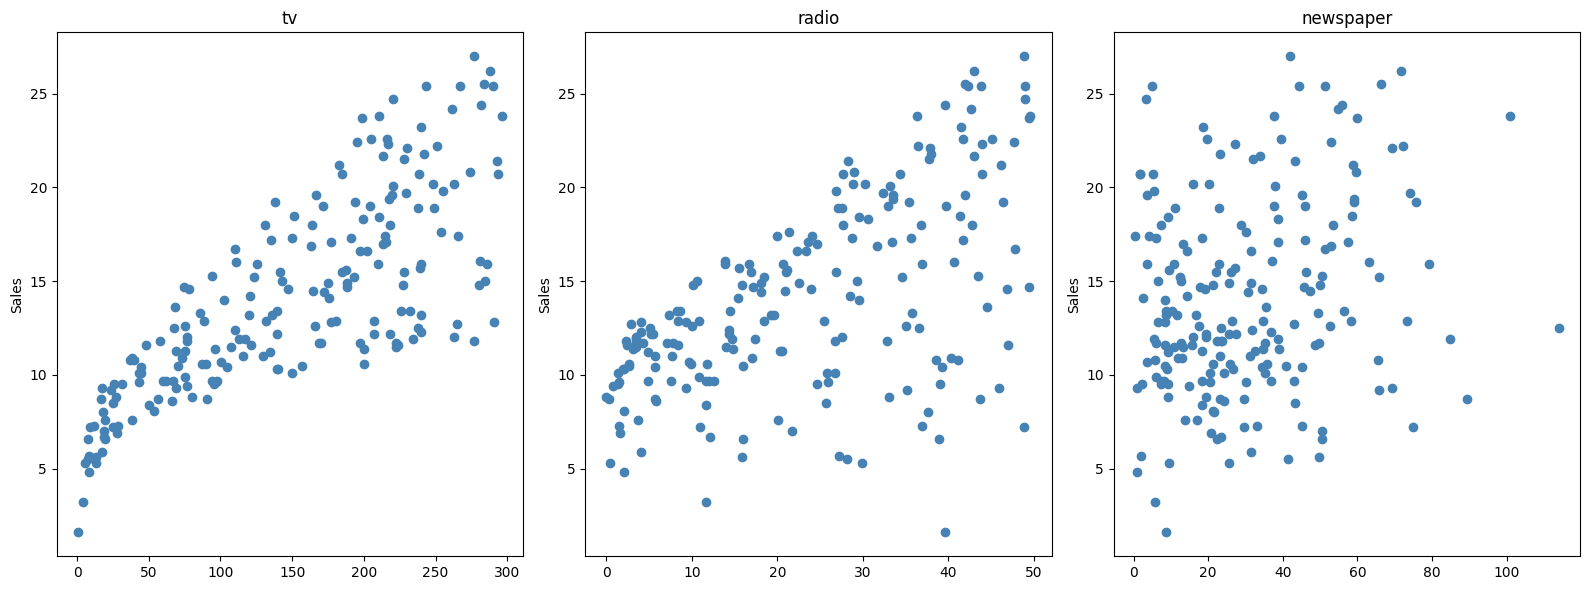

In [5]:
figure,axes=plt.subplots(1,3,figsize=(16,6))
for ax, col in zip(axes,['tv','radio','newspaper']):
    ax.scatter(df[col],df['sales'],color='steelblue')
    ax.set_ylabel('Sales')
    ax.set_title(col)
    plt.tight_layout()


y is cont, so we would go with linear regression

np.float64(0.4075714250767127)

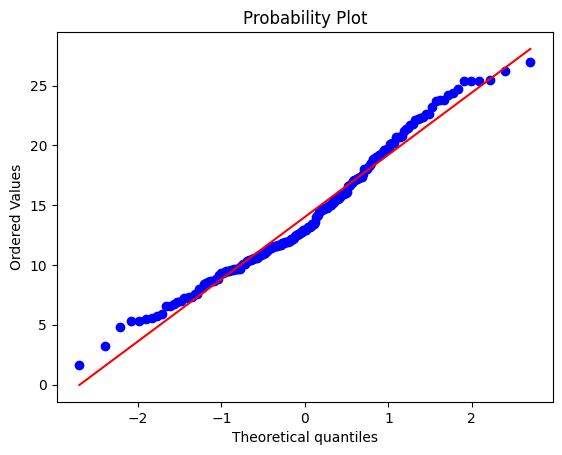

In [6]:
fig,axes=plt.subplots()
_=stats.probplot(df['sales'],dist='norm',plot=axes)
df['sales'].skew()

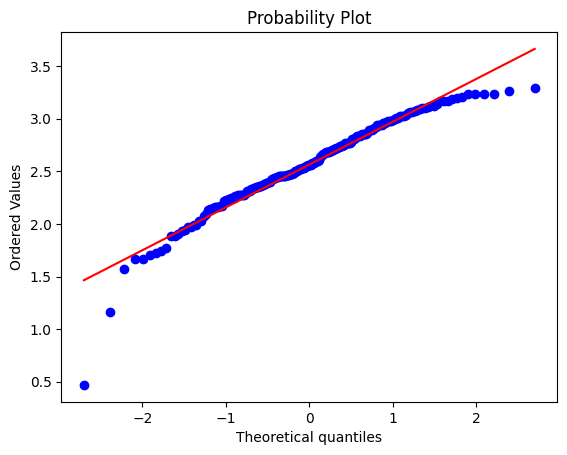

In [7]:
fig,axes=plt.subplots()
_=stats.probplot(np.log(df['sales']),dist='norm',plot=axes)


log transformation of y does fix the right skewness. lets hold onto that 

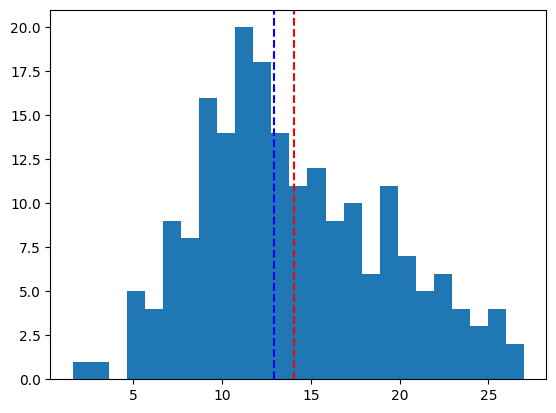

In [8]:
plt.hist(df['sales'],bins=25)
plt.axvline(df['sales'].mean(),c='r',linestyle='--')
plt.axvline(df['sales'].median(),c='b',linestyle='--')

{'whiskers': [<matplotlib.lines.Line2D at 0x1b807a52210>,
 'caps': [<matplotlib.lines.Line2D at 0x1b807a52490>,
 'boxes': [<matplotlib.patches.PathPatch at 0x1b805092660>],
 'medians': [<matplotlib.lines.Line2D at 0x1b807a52710>],
 'fliers': [<matplotlib.lines.Line2D at 0x1b807a52850>],
 'means': []}

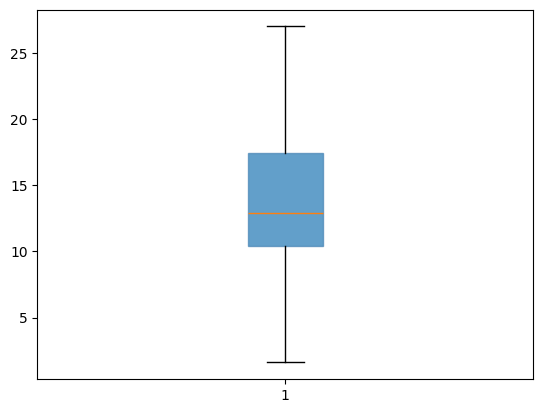

In [9]:
plt.boxplot(df['sales'],patch_artist=True,boxprops=dict(color='steelblue',alpha=0.7))

<Axes: >

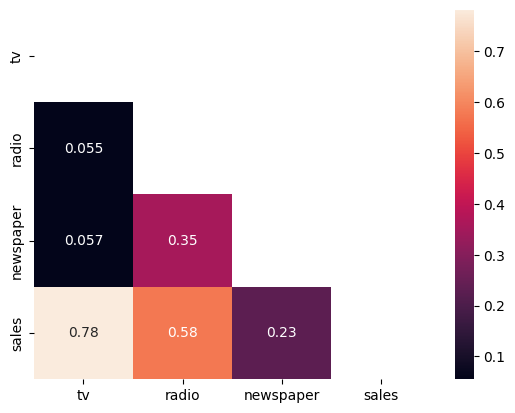

In [10]:
mask=np.triu(np.ones_like(df.corr()))
sns.heatmap(df.corr(),annot=True,mask=mask)

In [11]:
X=df.drop('sales',axis=1)
y=df['sales']

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

In [13]:
X_train.shape

(160, 3)

In [14]:
#checking multicollinearity 
sm.add_constant(X_train)
vif_data=pd.DataFrame({
    'features':X_train.columns,
    'VIF':[variance_inflation_factor(X_train.values,i) for i in range(X_train.shape[1])]    
})
vif_data.sort_values('VIF',ascending=False)

,features,VIF
1,radio,3.488819
2,newspaper,3.273569
0,tv,2.502896


In [15]:
#baseline

baselineModel=LinearRegression()
baselineModel.fit(X_train,y_train)

baseline_pred=baselineModel.predict(X_train)
baseline_residuals=y_train-baseline_pred

cv_scores=cross_val_score(baselineModel,X_train,y_train,scoring='neg_mean_squared_error',cv=KFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE))
baseline_mse_cv=-cv_scores.mean()
baseline_mse_cv, df['sales'].mean(),df['sales'].std()


(np.float64(2.879101210723536),
 np.float64(14.0225),
 np.float64(5.217456565710478))

,tv,radio,newspaper
5,8.7,48.9,75.0
130,0.7,39.6,8.7


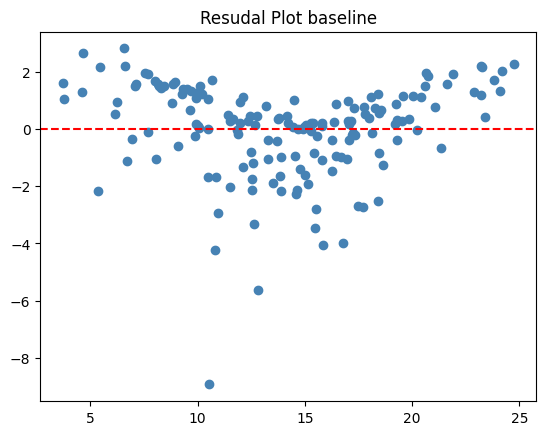

In [16]:
plt.scatter(baseline_pred,baseline_residuals,color='steelblue')
plt.axhline(y=0,c='r',linestyle='--')
plt.title('Resudal Plot baseline')

outlier_mask=np.abs(baseline_residuals)>3*baseline_residuals.std()
outliers=X_train[outlier_mask]
outliers

we see arc like shape in residual plot which suggests non linear relationships. there is some heteroscedascity as well .

np.float64(-1.6425561129054371)

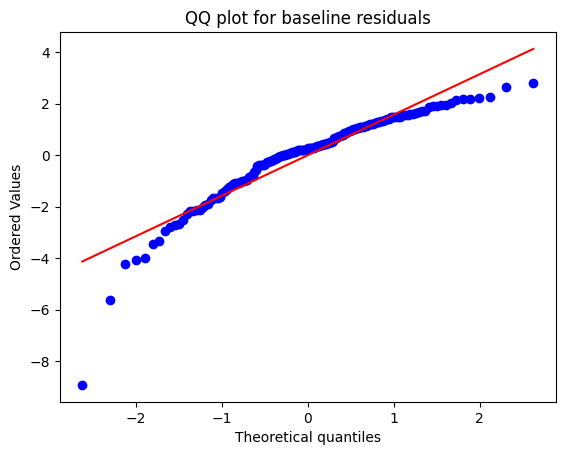

In [17]:
fig,axes=plt.subplots()
_=stats.probplot(baseline_residuals,dist='norm',plot=axes)
axes.set_title('QQ plot for baseline residuals')
baseline_residuals.skew()

non normality of residuals also confirmed in qq plot for residuals, left skew . kurtosis also is present

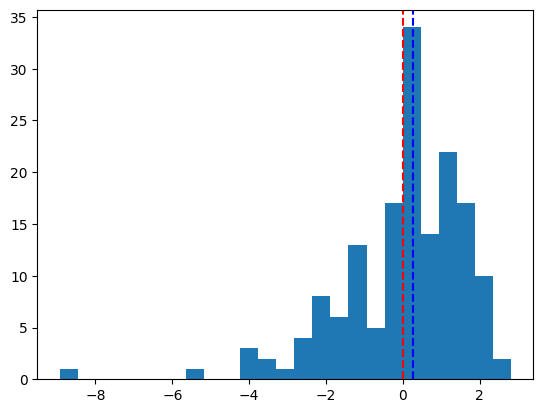

In [18]:
plt.hist(baseline_residuals,bins=25)
plt.axvline(baseline_residuals.mean(),c='r',linestyle='--')
plt.axvline(baseline_residuals.median(),c='b',linestyle='--')

confirmation of left skew and kurtosis

(1.0, 5.0)

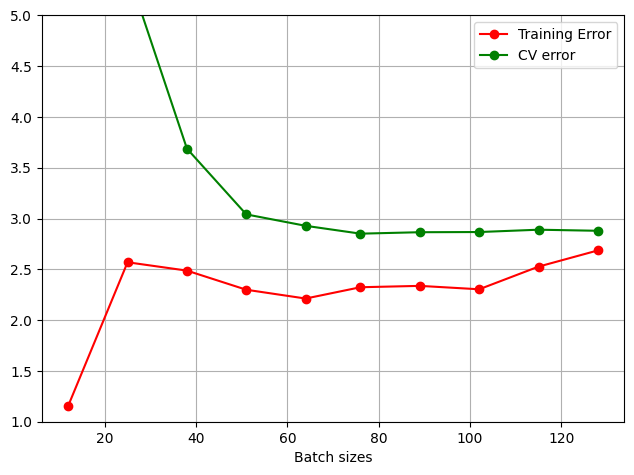

In [19]:
train_sizes,train_scrores,test_scores=learning_curve(baselineModel,X_train,y_train,cv=KFold(5,shuffle=True,random_state=RANDOM_STATE),scoring='neg_mean_squared_error',train_sizes=np.linspace(0.1,1,10))
plt.figure()
plt.plot(train_sizes,-train_scrores.mean(axis=1),'o-',c='r',label="Training Error")
plt.plot(train_sizes,-test_scores.mean(axis=1),'o-',c='g',label='CV error')
plt.xlabel('Batch sizes')
plt.grid(True);plt.legend(loc='best');plt.tight_layout();plt.ylim(1,5)

confirmation of high bias

In [20]:
pipe=Pipeline([('poly',PolynomialFeatures(include_bias=False)),
               ('scalar',StandardScaler()),
               ('model',LinearRegression())])
pipe.fit(X_train,y_train)

param_grid={'poly__degree':np.arange(1,10),
            'model__fit_intercept':[True,False]}

grid=GridSearchCV(pipe,param_grid,scoring='neg_mean_squared_error',cv=KFold(5,shuffle=True,random_state=RANDOM_STATE),return_train_score=True)
grid.fit(X_train,y_train)
best_degree=int(grid.best_params_['poly__degree'])
grid.best_score_,grid.best_params_



feature_names=pipe['poly'].get_feature_names_out(input_features=X_train.columns)
feature_names


array(['tv', 'radio', 'newspaper', 'tv^2', 'tv radio', 'tv newspaper',
       'radio^2', 'radio newspaper', 'newspaper^2'], dtype=object)

In [21]:
#lets verify at which degree does the overfit start to happen
pd.set_option('display.float_format','{:,.4f}'.format)

results=pd.DataFrame(grid.cv_results_)
results.columns
fi_true=results[results['param_model__fit_intercept']==True].copy()
fi_true['gap']=(-fi_true['mean_train_score'])-(-fi_true['mean_test_score'])
fi_true[['param_poly__degree','mean_test_score','mean_train_score','gap']]

,param_poly__degree,mean_test_score,mean_train_score,gap
0,1,-2.8791,-2.6859,-0.1932
1,2,-0.5344,-0.3428,-0.1916
2,3,-0.5491,-0.1952,-0.3538
3,4,-0.8957,-0.1122,-0.7835
4,5,-14.3075,-0.0514,-14.2562
5,6,-1.0899,-0.0297,-1.0601
6,7,"-125,573.5885",-0.0051,"-125,573.5834"
7,8,"-4,644,752.5549",-0.0000,"-4,644,752.5549"
8,9,"-14,878,955.5378",-0.0000,"-14,878,955.5378"


degree 2 is the best degree

In [22]:
pipe_poly=Pipeline([('poly',PolynomialFeatures(degree=best_degree,include_bias=False)),
                    ('scalar',StandardScaler()),
                    ('model',LinearRegression(fit_intercept=True))])

pipe_poly.fit(X_train,y_train)

poly_cv_scores=cross_val_score(pipe_poly,X_train,y_train,cv=KFold(5,shuffle=True,random_state=RANDOM_STATE),scoring='neg_mean_squared_error')
poly_cv_error=-poly_cv_scores.mean()
poly_cv_error



np.float64(0.5343553334694097)

In [37]:

feature_names=pipe_poly['poly'].get_feature_names_out(input_features=X_train.columns)
features_coefficients=pd.DataFrame({'feature_names':feature_names,
                                    'values':pipe_poly['model'].coef_}).sort_values('values',key=abs,ascending=False)
features_coefficients

,feature_names,values
0,tv,4.4800
4,tv radio,3.6792
3,tv^2,-2.8553
5,tv newspaper,-0.3447
1,radio,0.2523
2,newspaper,0.2145
7,radio newspaper,0.1113
6,radio^2,0.0966
8,newspaper^2,0.0443


(0.0, 0.65)

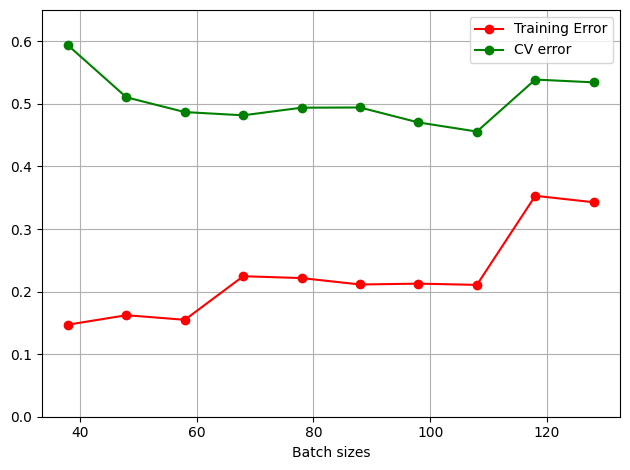

In [24]:
train_sizes_p,train_scores_p,test_scores_p=learning_curve(pipe_poly,X_train,y_train,cv=KFold(5,shuffle=True,random_state=RANDOM_STATE),train_sizes=np.linspace(0.3,1,10),scoring='neg_mean_squared_error',random_state=RANDOM_STATE)

plt.figure()
plt.plot(train_sizes_p,-train_scores_p.mean(axis=1),'o-',c='r',label="Training Error")
plt.plot(train_sizes_p,-test_scores_p.mean(axis=1),'o-',c='g',label='CV error')
plt.xlabel('Batch sizes')
plt.grid(True);plt.legend(loc='best');plt.tight_layout();plt.ylim(0,.65)

lil bit of overfitting lets see if regularization helps

In [25]:
cv_folds=KFold(5,shuffle=True,random_state=RANDOM_STATE)
alphas=np.logspace(-3,3,50)

def tune_hyperparameters(model):
    p=Pipeline([('poly',PolynomialFeatures(degree=best_degree,include_bias=False)),
                ('scalar',StandardScaler()),
                ('model',model)])
    if isinstance(model, (Ridge,Lasso)):
        param_grid={'model__alpha':alphas}
    else:
        param_grid={'model__alpha':alphas,
                    'model__l1_ratio':[0.1,.3,.5,.7,.9,.95,1]}
    g=GridSearchCV(p,param_grid,scoring='neg_mean_squared_error',cv=cv_folds)
    g.fit(X_train,y_train)

    return g.best_params_,-g.best_score_

ridge_bestParams,ridge_cv_mse=tune_hyperparameters(Ridge())
lasso_bestParams,lasso_cv_mse=tune_hyperparameters(Lasso(max_iter=20000))
elasticNet_bestParams,elasticNet_cv_mse=tune_hyperparameters(ElasticNet(max_iter=200000))

ridge_alpha=ridge_bestParams['model__alpha']
lasso_alpha=lasso_bestParams['model__alpha']
print(f'ridge  best alpha={ridge_alpha:.5f}  CV MSE={ridge_cv_mse:.4f}')
print(f'lasso  best alpha={lasso_alpha:.5f}  CV MSE={lasso_cv_mse:.4f}')
print(f'ElasticNet  best params={elasticNet_bestParams}  CV MSE={elasticNet_cv_mse:.4f}')


ridge  best alpha=0.15999  CV MSE=0.5329
lasso  best alpha=0.00954  CV MSE=0.5022
ElasticNet  best params={'model__alpha': np.float64(0.009540954763499945), 'model__l1_ratio': 1}  CV MSE=0.5022


In [26]:
final_choices={'poly':pipe_poly,
               'lasso':Pipeline([('poly',PolynomialFeatures(degree=best_degree,include_bias=False)),
                                 ('scalar',StandardScaler()),
                                 ('model',Lasso(alpha=lasso_alpha,max_iter=20000))]),
                'ridge':Pipeline([('poly',PolynomialFeatures(degree=best_degree,include_bias=False)),
                                 ('scalar',StandardScaler()),
                                 ('model',Ridge(alpha=ridge_alpha))])
                                 }
cv_table={}

for name, model in final_choices.items():
    s=cross_val_score(model,X_train,y_train,scoring='neg_mean_squared_error',cv=cv_folds)
    cv_table[name]=-s.mean(),s.std()
    print(f'{name:10s}  CV MSE = {-s.mean():.4f}  (+/- {s.std():.4f})')

winner=min(cv_table, key=lambda k : cv_table[k][0])
winner,cv_table

poly        CV MSE = 0.5344  (+/- 0.4635)
lasso       CV MSE = 0.5022  (+/- 0.4988)
ridge       CV MSE = 0.5329  (+/- 0.4900)


('lasso',
 {'poly': (np.float64(0.5343553334694097), np.float64(0.46349273930723034)),
  'lasso': (np.float64(0.5022305201200311), np.float64(0.49878103140300656)),
  'ridge': (np.float64(0.5329104857772589), np.float64(0.48995854043639436))})

In [27]:
final_pipeline=final_choices[winner]
final_pipeline.fit(X_train,y_train)

feature_namesFinal=final_pipeline['poly'].get_feature_names_out(input_features=X_train.columns)
feature_coeff=pd.DataFrame({'feature_names':feature_namesFinal,
                            'values':final_pipeline['model'].coef_}).sort_values('values',key=abs,ascending=False)
feature_coeff



,feature_names,values
0,tv,4.1228
4,tv radio,3.6164
3,tv^2,-2.5499
1,radio,0.3126
5,tv newspaper,-0.1818
7,radio newspaper,0.1253
2,newspaper,0.1188
6,radio^2,0.0643
8,newspaper^2,0.0000


Text(0.5, 1.0, 'Residual Plot (Lasso with Poly features degree2)')

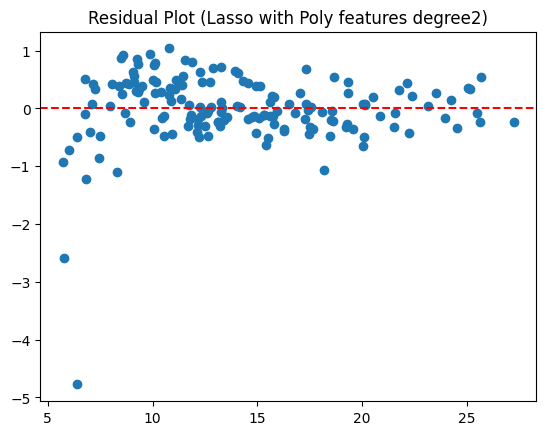

In [28]:
final_tr_pred=final_pipeline.predict(X_train)
final_resudals=y_train-final_tr_pred

plt.figure()
plt.scatter(final_tr_pred,final_resudals)
plt.axhline(y=0,c='r',linestyle='--')
plt.title('Residual Plot (Lasso with Poly features degree2)')

(np.float64(-3.4640730146536387), np.float64(24.340253043788337))

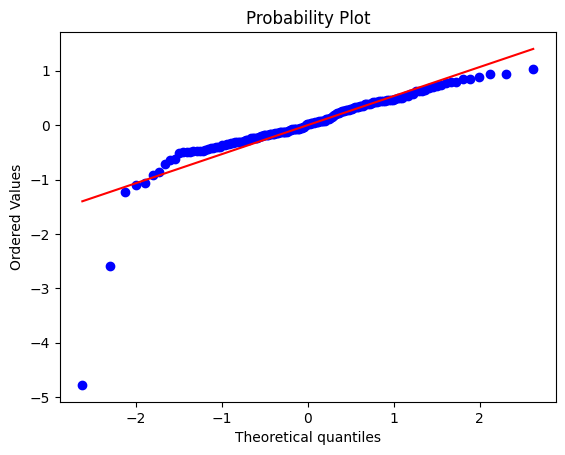

In [29]:
figure,axes=plt.subplots()
_=stats.probplot(final_resudals,dist='norm',plot=axes)
final_resudals.skew(),final_resudals.kurt()

(0.0, 0.65)

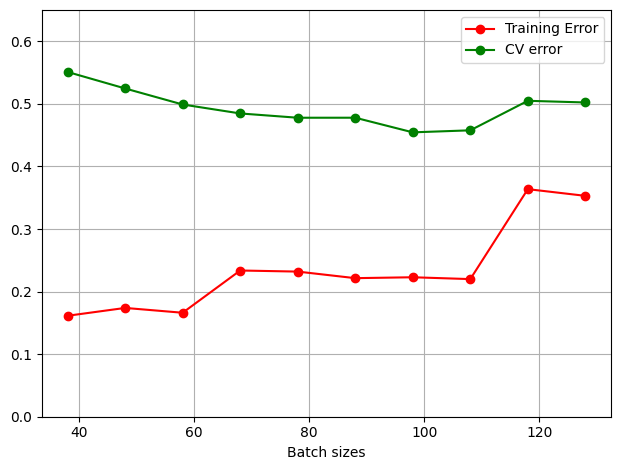

In [30]:
train_sizes_f,train_scores_f,test_scores_f=learning_curve(final_pipeline,X_train,y_train,cv=cv_folds,scoring='neg_mean_squared_error',random_state=RANDOM_STATE,train_sizes=np.linspace(0.3,1,10))
plt.plot(train_sizes_f,-train_scores_f.mean(axis=1),'o-',c='r',label="Training Error")
plt.plot(train_sizes_f,-test_scores_f.mean(axis=1),'o-',c='g',label='CV error')
plt.xlabel('Batch sizes')
plt.grid(True);plt.legend(loc='best');plt.tight_layout();plt.ylim(0,.65)



In [31]:
#final stats to report
mae=mean_absolute_error(y_test,final_pipeline.predict(X_test))
mse=mean_squared_error(y_test,final_pipeline.predict(X_test))
RMSE=np.sqrt(mse)
r2= r2_score(y_test,final_pipeline.predict(X_test))
mae, mse, RMSE, r2

(0.48520674277173564,
 0.3720085929380641,
 np.float64(0.6099250715768816),
 0.9882139975604627)

In [32]:
final_pipeline.fit(X,y)
joblib.dump(final_pipeline,'Advertising_model_final_predict.joblib')
print('Advertising_model_final_predict.joblib saved' )

Advertising_model_final_predict.joblib saved


Model Interpretation

In [33]:
train_df=X_train.copy();train_df['sales']=y_train

#mean centring for cond no
train_df['tv_c'] = train_df['tv'] - train_df['tv'].mean()
train_df['radio_c'] = train_df['radio'] - train_df['radio'].mean()

ols=smf.ols('sales~tv_c*radio_c+newspaper',data=train_df).fit(cov_type='HC3') #since there was heteroscadescity in residual plot. so HC3
rlm=smf.rlm('sales~tv_c*radio_c+newspaper',data=train_df,M=sm.robust.norms.HuberT()).fit()

print(ols.summary())

print(rlm.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.966
Model:                            OLS   Adj. R-squared:                  0.965
Method:                 Least Squares   F-statistic:                     1205.
Date:                Wed, 15 Jul 2026   Prob (F-statistic):          1.31e-115
Time:                        22:41:02   Log-Likelihood:                -217.79
No. Observations:                 160   AIC:                             445.6
Df Residuals:                     155   BIC:                             461.0
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       13.9727      0.205     68.179   

we see that rlm and ols coefficients are close, that means the heteroscedascity is from outliers . we could use log transform , but use of HC3 makes our p values and confidence intervals valid. and saves us the time for back transformations on predictions, also the bias correction is avoided.
our lasso and ols model agrees as well on the interactions between tv and radio , also on the fact that newspaper is not important and it could be dropped.

In [34]:
test_df = X_test.copy()
test_df['tv_c'] = test_df['tv'] - test_df['tv'].mean()
test_df['radio_c'] = test_df['radio'] - test_df['radio'].mean()
ols_pred = ols.get_prediction(test_df).summary_frame(alpha=0.05)

ols_pred =ols_pred.rename(columns={
    'mean': 'prediction',
    'mean_ci_lower': 'mean_CI_lower', 'mean_ci_upper': 'mean_CI_upper',
    'obs_ci_lower': 'pred_interval_lower', 'obs_ci_upper': 'pred_interval_upper'})
ols_pred[['prediction', 'mean_CI_lower', 'mean_CI_upper',
      'pred_interval_lower', 'pred_interval_upper']].head(10)

,prediction,mean_CI_lower,mean_CI_upper,pred_interval_lower,pred_interval_upper
0,16.8016,16.5735,17.0298,14.9083,18.6950
1,22.5322,22.2253,22.8391,20.6277,24.4367
2,22.1822,21.7460,22.6183,20.2527,24.1117
3,9.4209,8.7832,10.0586,7.4361,11.4057
4,24.4872,24.0469,24.9275,22.5567,26.4177
5,12.7616,12.4030,13.1202,10.8481,14.6751
6,22.8776,22.6051,23.1502,20.9784,24.7769
7,8.9437,8.5445,9.3430,7.0222,10.8652
8,11.7420,11.4338,12.0502,9.8373,13.6467
9,15.2355,15.1182,15.3528,13.3522,17.1187


In [35]:
ols_pred.columns

Index(['prediction', 'mean_se', 'mean_CI_lower', 'mean_CI_upper',
       'pred_interval_lower', 'pred_interval_upper'],
      dtype='object')

In [36]:
ols_pred = ols.get_prediction(test_df).summary_frame(alpha=0.05)
lasso_pred = final_pipeline.predict(X_test)

 # Check if Lasso predictions fall within OLS prediction intervals
within_interval = (
    (lasso_pred > ols_pred['obs_ci_lower']) & 
    (lasso_pred < ols_pred['obs_ci_upper'])
)
print(within_interval.mean())

0.975


here also we can see that lasso predictions fall within OLS predictions , 97 percent of time. So sanity is success